In [ ]:
!pip install micom tqdm cobra

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.0/142.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 80.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.3/50.3 MB 13.5 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
import numpy as np
import cobra
from micom import Community
from micom.workflows import build
from micom import load_pickle
from micom.workflows import grow
from micom.workflows import tradeoff
from micom.workflows import complete_community_medium
from micom.interaction import interactions
from micom.interaction import summarize_interactions
from micom.interaction import MES
from micom.measures import production_rates
from tqdm import tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

data = pd.read_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/community_micom_complete.csv')
data

,id,genus,species,reactions,metabolites,file,sample_id,abundance
0,mcaps,Methylococcus,Methylococcus capsulatus Bath,915,880,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_1_1,1000
1,agitata,Dechloromonas,Dechloromonas agitata is5,1770,1439,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_1_1,0
2,mcaps,Methylococcus,Methylococcus capsulatus Bath,915,880,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_1_2,900
3,agitata,Dechloromonas,Dechloromonas agitata is5,1770,1439,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_1_2,100
4,mcaps,Methylococcus,Methylococcus capsulatus Bath,915,880,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_1_3,800
...,...,...,...,...,...,...,...,...
83,agitata,Dechloromonas,Dechloromonas agitata is5,1770,1439,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_4_9,800
84,ob3,Methylosinus,Methylosinus trichosporium OB3b,1048,1020,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_4_10,100
85,agitata,Dechloromonas,Dechloromonas agitata is5,1770,1439,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_4_10,900
86,ob3,Methylosinus,Methylosinus trichosporium OB3b,1048,1020,/content/drive/MyDrive/sup_notebooks/final_mod...,sample_4_11,0


In [ ]:
import os
import pandas as pd
from micom import Community

out_folder = "path/"
os.makedirs(out_folder, exist_ok=True)

data["file"] = data["file"].str.strip()
data["id"] = data["id"].str.strip()

for sample_id, sample_data in data.groupby("sample_id"):
    out_path = os.path.join(out_folder, f"{sample_id}.pickle")

    if os.path.exists(out_path):
        print(f"Skipping {sample_id}, already exists.")
        continue

    sample_data = sample_data.reset_index(drop=True)

    print(f"Building community for {sample_id}...")
    print(sample_data[["id", "file"]])

    com = Community(sample_data, progress=False)
    com.to_pickle(out_path)
    print(f"Saved: {out_path}")

Skipping sample_1_1, already exists.
Skipping sample_1_10, already exists.
Skipping sample_1_11, already exists.
Skipping sample_1_2, already exists.
Skipping sample_1_3, already exists.
Skipping sample_1_4, already exists.
Skipping sample_1_5, already exists.
Skipping sample_1_6, already exists.
Skipping sample_1_7, already exists.
Skipping sample_1_8, already exists.
Skipping sample_1_9, already exists.
Skipping sample_2_1, already exists.
Skipping sample_2_10, already exists.
Skipping sample_2_11, already exists.
Skipping sample_2_2, already exists.
Skipping sample_2_3, already exists.
Skipping sample_2_4, already exists.
Skipping sample_2_5, already exists.
Skipping sample_2_6, already exists.
Skipping sample_2_7, already exists.
Skipping sample_2_8, already exists.
Skipping sample_2_9, already exists.
Skipping sample_3_1, already exists.
Skipping sample_3_10, already exists.
Skipping sample_3_11, already exists.
Skipping sample_3_2, already exists.
Skipping sample_3_3, already exi

In [ ]:
import os
import glob
import pandas as pd
from micom import load_pickle

out_folder = "/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/"

pickle_files = glob.glob(os.path.join(out_folder, "*.pickle"))

records = []

for pickle_path in sorted(pickle_files):
    sample_id = os.path.basename(pickle_path).replace(".pickle", "")

    com = load_pickle(pickle_path)

    n_reactions = len(com.reactions)
    n_metabolites = len(com.metabolites)

    file_name = os.path.basename(pickle_path)

    records.append({
        "reactions": n_reactions,
        "metabolites": n_metabolites,
        "file": file_name,
        "sample_id": sample_id
    })

manifest_df = pd.DataFrame(records)

manifest_path = os.path.join(out_folder, "manifest.csv")
manifest_df.to_csv(manifest_path, index=False)

manifest_df

,reactions,metabolites,file,sample_id
0,964,871,sample_1_1.pickle,sample_1_1
1,2840,2416,sample_1_10.pickle,sample_1_10
2,1918,1587,sample_1_11.pickle,sample_1_11
3,2840,2416,sample_1_2.pickle,sample_1_2
4,2840,2416,sample_1_3.pickle,sample_1_3
5,2840,2416,sample_1_4.pickle,sample_1_4
6,2840,2416,sample_1_5.pickle,sample_1_5
7,2840,2416,sample_1_6.pickle,sample_1_6
8,2840,2416,sample_1_7.pickle,sample_1_7
9,2840,2416,sample_1_8.pickle,sample_1_8


In [ ]:
manifest_df = pd.read_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/manifest.csv')
manifest_df

,reactions,metabolites,file,sample_id
0,964,871,sample_1_1.pickle,sample_1_1
1,2840,2416,sample_1_10.pickle,sample_1_10
2,1918,1587,sample_1_11.pickle,sample_1_11
3,2840,2416,sample_1_2.pickle,sample_1_2
4,2840,2416,sample_1_3.pickle,sample_1_3
5,2840,2416,sample_1_4.pickle,sample_1_4
6,2840,2416,sample_1_5.pickle,sample_1_5
7,2840,2416,sample_1_6.pickle,sample_1_6
8,2840,2416,sample_1_7.pickle,sample_1_7
9,2840,2416,sample_1_8.pickle,sample_1_8


In [ ]:
from micom.workflows import grow

out_folder = '/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/'

data["id"] = data["id"].str.strip()

methanotrophs = {
    "mcaps": 18.46,
    "zr20": 11.7,
    "album": 8.0,
    "ob3": 14.9
}

sample_meth_flux = {}
for sample_id, group in data.groupby("sample_id"):
    meth_id = None
    for org_id in group["id"]:
        if org_id in methanotrophs:
            meth_id = org_id
            break
    if meth_id is None:
        raise ValueError(f"В образце {sample_id} не найден метанотроф")
    sample_meth_flux[sample_id] = methanotrophs[meth_id]

base_medium = {
    "EX_ca2_m": 1000.0,
    "EX_cd2_m": 1000.0,
    "EX_cl_m": 1000.0,
    "EX_co_m": 1000.0,
    "EX_cobalt2_m": 1000.0,
    "EX_cu2_m": 1000.0,
    "EX_fe2_m": 1000.0,
    "EX_h2o_m": 1000.0,
    "EX_h_m": 1000.0,
    "EX_k_m": 1000.0,
    "EX_mg2_m": 1000.0,
    "EX_mn2_m": 1000.0,
    "EX_na1_m": 1000.0,
    "EX_ni2_m": 1000.0,
    "EX_nh3_m": 1000.0,
    "EX_pi_m": 1000.0,
    "EX_so4_m": 1000.0,
    "EX_zn2_m": 1000.0,
    "EX_fe3_m": 1000.0,
    "EX_cro4_m": 1000.0,
    "EX_mobd_m": 1000.0,
    "EX_hg2_m": 1000.0,
    "EX_aso4_m": 1000.0,
    "EX_co2_m": 1000.0,
    "EX_h2_m": 1000.0,
    "EX_h2s_m": 1000.0,
    "EX_o2_m": 1000.0,
    "EX_clo4_m": 1000.0
}

all_results = []

for sample_id in data["sample_id"].unique():

    pickle_path = os.path.join(out_folder, f"{sample_id}.pickle")
    com = load_pickle(pickle_path)

    taxa = list(com.taxa)
    if len(taxa) != 2:
        continue

    medium = base_medium.copy()
    medium["EX_ch4_m"] = sample_meth_flux[sample_id]

    try:
        com.objective.expression
        com.medium = medium
        sol = com.optimize()

        if sol is not None and sol.status == "optimal":
            growth_rate = sol.growth_rate

            growth_rates = sol.members['growth_rate']
            growth1 = growth_rates.get(taxa[0], None)
            growth2 = growth_rates.get(taxa[1], None)

            all_results.append({
                "sample_id": sample_id,
                "taxon1": taxa[0],
                "taxon2": taxa[1],
                "growth_rate": growth_rate,
                "growth_rate1": growth1,
                "growth_rate2": growth2,
                "status": sol.status
            })
        else:
            print(f"{sample_id}: {sol.status if sol else 'None'}")
            all_results.append({
                "sample_id": sample_id,
                "taxon1": taxa[0],
                "taxon2": taxa[1],
                "growth_rate": None,
                "growth_rate1": None,
                "growth_rate2": None,
                "status": sol.status if sol else "no_solution"
            })
    except Exception as e:
        print(f"error {sample_id}: {e}")
        all_results.append({
            "sample_id": sample_id,
            "taxon1": taxa[0],
            "taxon2": taxa[1],
            "growth_rate": None,
            "growth_rate1": None,
            "growth_rate2": None,
            "status": f"error: {str(e)[:50]}"
        })

In [ ]:
results_df = pd.DataFrame(all_results)
results_df

,sample_id,taxon1,taxon2,growth_rate,growth_rate1,growth_rate2,status
0,sample_1_2,mcaps,agitata,4.234751e-01,0.470528,0.000000e+00,optimal
1,sample_1_3,mcaps,agitata,5.041390e-01,0.630174,0.000000e+00,optimal
2,sample_1_4,mcaps,agitata,5.705194e-01,0.815028,0.000000e+00,optimal
3,sample_1_5,mcaps,agitata,6.347454e-01,1.057909,0.000000e+00,optimal
4,sample_1_6,mcaps,agitata,6.989713e-01,1.397943,0.000000e+00,optimal
5,sample_1_7,mcaps,agitata,7.621636e-01,1.905409,0.000000e+00,optimal
6,sample_1_8,mcaps,agitata,8.138281e-01,2.549656,6.990200e-02,optimal
7,sample_1_9,mcaps,agitata,6.737945e-01,1.331301,5.094178e-01,optimal
8,sample_1_10,mcaps,agitata,3.952619e-01,0.000000,4.391799e-01,optimal
9,sample_2_2,zr20,agitata,2.804417e-01,0.043084,2.416659e+00,optimal


In [ ]:
results_df.to_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/com_growth_on_medium.csv')

In [ ]:
manifest_df = manifest_df[manifest_df["sample_id"].isin(results_df["sample_id"])] 
manifest_df

,reactions,metabolites,file,sample_id
1,2840,2416,sample_1_10.pickle,sample_1_10
3,2840,2416,sample_1_2.pickle,sample_1_2
4,2840,2416,sample_1_3.pickle,sample_1_3
5,2840,2416,sample_1_4.pickle,sample_1_4
6,2840,2416,sample_1_5.pickle,sample_1_5
7,2840,2416,sample_1_6.pickle,sample_1_6
8,2840,2416,sample_1_7.pickle,sample_1_7
9,2840,2416,sample_1_8.pickle,sample_1_8
10,2840,2416,sample_1_9.pickle,sample_1_9
12,2369,2018,sample_2_10.pickle,sample_2_10


In [ ]:
manifest_df.to_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/manifest.csv')

NameError: name 'manifest_df' is not defined

In [ ]:
manifest_df

,reactions,metabolites,file,sample_id
1,2840,2416,sample_1_10.pickle,sample_1_10
3,2840,2416,sample_1_2.pickle,sample_1_2
4,2840,2416,sample_1_3.pickle,sample_1_3
5,2840,2416,sample_1_4.pickle,sample_1_4
6,2840,2416,sample_1_5.pickle,sample_1_5
7,2840,2416,sample_1_6.pickle,sample_1_6
8,2840,2416,sample_1_7.pickle,sample_1_7
9,2840,2416,sample_1_8.pickle,sample_1_8
10,2840,2416,sample_1_9.pickle,sample_1_9
12,2369,2018,sample_2_10.pickle,sample_2_10


In [ ]:
manifest_df = pd.read_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/manifest.csv')

In [ ]:
results_df = pd.read_csv('/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/com_growth_on_medium.csv')

In [ ]:
import numpy as np

results_df = results_df[
    ~((results_df['growth_rate1'].isna()) | (results_df['growth_rate1'] == 0) |
      (results_df['growth_rate2'].isna()) | (results_df['growth_rate2'] == 0))
]
results_df

,Unnamed: 0,sample_id,taxon1,taxon2,growth_rate,growth_rate1,growth_rate2,status
6,6,sample_1_8,mcaps,agitata,0.813828,2.549656,0.069902,optimal
7,7,sample_1_9,mcaps,agitata,0.673795,1.331301,0.509418,optimal
9,9,sample_2_2,zr20,agitata,0.280442,0.043084,2.416659,optimal
10,10,sample_2_3,zr20,agitata,0.340607,0.052844,1.491657,optimal
18,18,sample_3_2,album,agitata,0.936059,0.687874,3.169723,optimal
19,19,sample_3_3,album,agitata,0.903169,0.342571,3.145560,optimal


In [ ]:
manifest_df = manifest_df[manifest_df["sample_id"].isin(results_df["sample_id"])]
manifest_df

,reactions,metabolites,file,sample_id
9,2840,2416,sample_1_8.pickle,sample_1_8
10,2840,2416,sample_1_9.pickle,sample_1_9
14,2369,2018,sample_2_2.pickle,sample_2_2
15,2369,2018,sample_2_3.pickle,sample_2_3
25,3300,2987,sample_3_2.pickle,sample_3_2
26,3300,2987,sample_3_3.pickle,sample_3_3


In [ ]:
from micom.workflows import grow
import os
import pandas as pd

data["id"] = data["id"].str.strip()

methanotrophs = {
    "mcaps": 18.46,
    "zr20": 11.7,
    "album": 8.0,
    "ob3": 14.9
}

sample_meth_flux = {}
for sample_id, group in data.groupby("sample_id"):
    meth_id = None
    for org_id in group["id"]:
        if org_id in methanotrophs:
            meth_id = org_id
            break
    if meth_id is None:
        raise ValueError(f"error {sample_id}")
    sample_meth_flux[sample_id] = methanotrophs[meth_id]

base_medium = {
    "EX_ca2_m": 1000.0,
    "EX_cd2_m": 1000.0,
    "EX_cl_m": 1000.0,
    "EX_co_m": 1000.0,
    "EX_cobalt2_m": 1000.0,
    "EX_cu2_m": 1000.0,
    "EX_fe2_m": 1000.0,
    "EX_h2o_m": 1000.0,
    "EX_h_m": 1000.0,
    "EX_k_m": 1000.0,
    "EX_mg2_m": 1000.0,
    "EX_mn2_m": 1000.0,
    "EX_na1_m": 1000.0,
    "EX_ni2_m": 1000.0,
    "EX_nh3_m": 1000.0,
    "EX_pi_m": 1000.0,
    "EX_so4_m": 1000.0,
    "EX_zn2_m": 1000.0,
    "EX_fe3_m": 1000.0,
    "EX_cro4_m": 1000.0,
    "EX_mobd_m": 1000.0,
    "EX_hg2_m": 1000.0,
    "EX_aso4_m": 1000.0,
    "EX_co2_m": 1000.0,
    "EX_h2_m": 1000.0,
    "EX_o2_m": 1000.0,
    "EX_h2s_m": 1000.0,
    "EX_clo4_m": 1000.0
}

medium_records = []
for sample_id in manifest_df["sample_id"]: 
    ch4_flux = sample_meth_flux[sample_id]
    med = base_medium.copy()
    med["EX_ch4_m"] = ch4_flux
    for reaction, flux in med.items():
        medium_records.append({
            "sample_id": sample_id,
            "reaction": reaction,
            "flux": flux
        })

medium_df = pd.DataFrame(medium_records)

output_dir = "/content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom"
os.makedirs(output_dir, exist_ok=True)

for sample_id in manifest_df["sample_id"].unique():
    print(f"{sample_id}")

    manifest_subset = manifest_df[manifest_df["sample_id"] == sample_id].copy()

    medium_subset = medium_df[medium_df["sample_id"] == sample_id].copy()

    res = grow(
        manifest_subset,
        model_folder="/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic",
        medium=medium_subset,
        tradeoff=0.3,
        threads=2
    )

    out_file = os.path.join(output_dir, f"grow_results_micom_{sample_id}.zip")
    res.save(out_file)

Обработка образца sample_1_8


Output()

Результат сохранён: /content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom/grow_results_micom_sample_1_8.zip
Обработка образца sample_1_9


Output()

Результат сохранён: /content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom/grow_results_micom_sample_1_9.zip
Обработка образца sample_2_2


...

Результат сохранён: /content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom/grow_results_micom_sample_2_3.zip
Обработка образца sample_3_2


Output()

Результат сохранён: /content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom/grow_results_micom_sample_3_2.zip
Обработка образца sample_3_3


Output()

Результат сохранён: /content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom/grow_results_micom_sample_3_3.zip


In [ ]:
import os
import zipfile
import pandas as pd
import tempfile

input_dir = "/content/drive/MyDrive/sup_notebooks/final/dagitata/grow_results_micom"
output_dir = "/content/drive/MyDrive/sup_notebooks/final/dagitata/final_res_with_sample_id"
os.makedirs(output_dir, exist_ok=True)

all_annotations = []
all_exchanges = []
all_growth_rates = []

for zip_filename in os.listdir(input_dir):
    if not zip_filename.startswith("grow_results_micom_") or not zip_filename.endswith(".zip"):
        continue

    sample_id = zip_filename.replace("grow_results_micom_", "").replace(".zip", "")
    print(f"{zip_filename} -> sample_id = {sample_id}")

    zip_path = os.path.join(input_dir, zip_filename)

    with tempfile.TemporaryDirectory() as tmpdir:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(tmpdir)

        for root, dirs, files in os.walk(tmpdir):
            for file in files:
                if file.endswith(".csv"):
                    csv_path = os.path.join(root, file)
                    df = pd.read_csv(csv_path)

                    if 'sample_id' in df.columns:
                        df['sample_id'] = sample_id
                    else:
                        df.insert(0, 'sample_id', sample_id)

                    if file == "annotations.csv":
                        all_annotations.append(df)
                    elif file == "exchanges.csv":
                        all_exchanges.append(df)
                    elif file == "growth_rates.csv":
                        all_growth_rates.append(df)
                    else:
                        print(f"{file}")

if all_annotations:
    final_annotations = pd.concat(all_annotations, ignore_index=True)
    final_annotations.to_csv(os.path.join(output_dir, "annotations.csv"), index=False)
    print(f"{len(final_annotations)}")

if all_exchanges:
    final_exchanges = pd.concat(all_exchanges, ignore_index=True)
    final_exchanges.to_csv(os.path.join(output_dir, "exchanges.csv"), index=False)

if all_growth_rates:
    final_growth_rates = pd.concat(all_growth_rates, ignore_index=True)
    final_growth_rates.to_csv(os.path.join(output_dir, "growth_rates.csv"), index=False)

archive_path = os.path.join(output_dir, "final_results.zip")
with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for csv_file in ["annotations.csv", "exchanges.csv", "growth_rates.csv"]:
        file_path = os.path.join(output_dir, csv_file)
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=csv_file)
print(f"{archive_path}")

grow_results_micom_sample_3_2.zip -> sample_id = sample_3_2
grow_results_micom_sample_3_3.zip -> sample_id = sample_3_3
grow_results_micom_sample_2_2.zip -> sample_id = sample_2_2
grow_results_micom_sample_2_3.zip -> sample_id = sample_2_3
grow_results_micom_sample_1_8.zip -> sample_id = sample_1_8
grow_results_micom_sample_1_9.zip -> sample_id = sample_1_9
1940
Сохранено exchanges.csv: 390 строк
Сохранено growth_rates.csv: 12 строк
/content/drive/MyDrive/sup_notebooks/final/dagitata/final_res_with_sample_id/final_results.zip


In [ ]:
from micom.data import test_results
from micom.interaction import interactions

results = test_results()

In [ ]:
import zipfile
import pandas as pd
import os

zip_path = "/content/drive/MyDrive/sup_notebooks/final/dagitata/final_res_with_sample_id/final_results.zip"
out_path = "/content/drive/MyDrive/sup_notebooks/final/dagitata/final_res_with_sample_id/final_results_agitata.zip"

temp_dir = "/tmp/final_results_temp"
os.makedirs(temp_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.extractall(temp_dir)

annot_path = os.path.join(temp_dir, "annotations.csv")
df = pd.read_csv(annot_path)
if 'sample_id' in df.columns:
    df = df.drop(columns=['sample_id'])
    df.to_csv(annot_path, index=False)
    print("column sample_id removed from annotation.csv")
else:
    print("column sample_id not found")

with zipfile.ZipFile(out_path, 'w') as zf:
    for root, dirs, files in os.walk(temp_dir):
        for file in files:
            full_path = os.path.join(root, file)
            arcname = os.path.relpath(full_path, temp_dir)
            zf.write(full_path, arcname)

import shutil
shutil.rmtree(temp_dir)


results = results.load("/content/drive/MyDrive/sup_notebooks/final/dagitata/final_res_with_sample_id/final_results_agitata.zip")


column sample_id removed from annotation.csv


In [ ]:
import pandas as pd
import numpy as np

def count_non_empty(row):
    return row.notna().sum()

results.annotations['_info_score'] = results.annotations.apply(count_non_empty, axis=1)
results.annotations = results.annotations.sort_values('_info_score', ascending=False)
results.annotations = results.annotations.drop_duplicates(subset=['metabolite'], keep='first') #, 'reaction'
results.annotations = results.annotations.drop(columns=['_info_score'])
results.annotations = results.annotations.reset_index(drop=True)
results.annotations

,metabolite,name,molecular_weight,C_number,N_number,kegg.compound,inchi,chebi,reactomem,vmhm,...,envipath,envipathm,kegg.drug,keggd,lipidmapsm,lipidmaps,slm,sbo,biocyc,reaction
0,ac_m,Acetate-e,59.04402,2,0,C00033,"['[]', 'InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/...","['CHEBI:22169', 'CHEBI:13704', 'CHEBI:40486', ...","['R-ALL-1524044', 'R-ALL-29416', 'R-ALL-973711...","['ac', 'M_ac']",...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,D00010,"['D00010', 'M_D00010']",LMFA01010002,LMFA01010002,449.0,NaN,NaN,EX_ac_m
1,ac_e,Acetate-e,59.04402,2,0,C00033,"['[]', 'InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/...","['CHEBI:22169', 'CHEBI:13704', 'CHEBI:40486', ...","['R-ALL-1524044', 'R-ALL-29416', 'R-ALL-973711...","['ac', 'M_ac']",...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,D00010,"['D00010', 'M_D00010']",LMFA01010002,LMFA01010002,449.0,NaN,NaN,EX_ac_e
2,leu__L_m,L-Leucine-c,131.17292,6,1,"['C00123', 'C16439']","['[]', 'InChI=1S/C6H13NO2/c1-4(2)3-5(7)6(8)9/h...","['CHEBI:231582', 'CHEBI:43814', 'CHEBI:231578'...","['R-ALL-113580', 'R-ALL-29588', 'R-ALL-351964']","['M_leu_L', 'leu_L']",...,['650babc9-9d68-4b73-9332-11972ca26f7b/compoun...,['650babc9-9d68-4b73-9332-11972ca26f7b/compoun...,D00030,"['M_D00030', 'D00030']",LMFA01100048,LMFA01100048,NaN,NaN,NaN,EX_leu__L_m
3,val__L_m,L-Valine-e,117.14634,5,1,"['C00183', 'C16436']","['[]', 'InChI=1S/C5H11NO2/c1-3(2)4(6)5(7)8/h3-...","['CHEBI:27266', 'CHEBI:46484', 'CHEBI:176648',...","['R-ALL-29702', 'R-ALL-113540', 'R-ALL-351992']","['val_L', 'M_val_L']",...,['32de3cf4-e3e6-4168-956e-32fa5ddb0ce1/compoun...,['32de3cf4-e3e6-4168-956e-32fa5ddb0ce1/compoun...,D00039,"['M_D00039', 'D00039']",LMFA01100046,LMFA01100046,NaN,NaN,NaN,EX_val__L_m
4,leu__L_e,L-Leucine-c,131.17292,6,1,"['C00123', 'C16439']","['[]', 'InChI=1S/C6H13NO2/c1-4(2)3-5(7)6(8)9/h...","['CHEBI:231582', 'CHEBI:43814', 'CHEBI:231578'...","['R-ALL-113580', 'R-ALL-29588', 'R-ALL-351964']","['M_leu_L', 'leu_L']",...,['650babc9-9d68-4b73-9332-11972ca26f7b/compoun...,['650babc9-9d68-4b73-9332-11972ca26f7b/compoun...,D00030,"['M_D00030', 'D00030']",LMFA01100048,LMFA01100048,NaN,NaN,NaN,EX_leu__L_e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,clo3_e,Chlorate,83.45120,0,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_clo3_e
374,clo2_e,Chlorite,67.45180,0,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_clo2_e
375,c2h6_m,ethane,30.06904,2,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_c2h6_m
376,ham_m,hydroxylamine,33.02992,0,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_ham_m


In [ ]:
import micom
from micom.interaction import interactions

ints = interactions(results, taxa="agitata")
# ints = ints.sort_values(by="flux").head()
# ints

In [ ]:
from micom.interaction import summarize_interactions

summary = summarize_interactions(ints)
summary.head()

,sample_id,focal,partner,class,flux,mass_flux,C_flux,N_flux,n_ints
0,sample_1_8,agitata,mcaps,co-consumed,2.897765,0.089642,0.000000,0.331871,11
1,sample_1_8,agitata,mcaps,provided,31.742213,4.040304,121.795827,0.020657,5
2,sample_1_8,agitata,mcaps,received,65.190568,4.320085,135.192452,0.023878,6
3,sample_1_9,agitata,mcaps,co-consumed,2.479238,0.078391,0.000000,0.108201,10
4,sample_1_9,agitata,mcaps,provided,2.048147,0.090613,2.065310,0.006613,4


In [ ]:
full = interactions(results, taxa=None, threads=8)
full.shape

Output()

(198, 41)

In [ ]:
full_summary = summarize_interactions(full)
full_summary.shape

(36, 9)

In [ ]:
from micom.interaction import MES

scores = MES(results)
scores.head()

,metabolite,sample_id,MES,name,molecular_weight,C_number,N_number,kegg.compound,inchi,chebi,...,envipath,envipathm,kegg.drug,keggd,lipidmapsm,lipidmaps,slm,sbo,biocyc,reaction
0,4_Hydroxy_benzylalcohol_e,sample_3_2,0.0,4-Hydroxy-benzylalcohol-e,124.13722,7,0,NaN,[],NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_4_Hydroxy_benzylalcohol_e
1,4_Hydroxy_benzylalcohol_e,sample_3_3,0.0,4-Hydroxy-benzylalcohol-e,124.13722,7,0,NaN,[],NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EX_4_Hydroxy_benzylalcohol_e
2,ac_e,sample_2_2,1.0,Acetate-e,59.04402,2,0,C00033,"['[]', 'InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/...","['CHEBI:22169', 'CHEBI:13704', 'CHEBI:40486', ...",...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,D00010,"['D00010', 'M_D00010']",LMFA01010002,LMFA01010002,449.0,NaN,NaN,EX_ac_e
3,ac_e,sample_2_3,1.0,Acetate-e,59.04402,2,0,C00033,"['[]', 'InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/...","['CHEBI:22169', 'CHEBI:13704', 'CHEBI:40486', ...",...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,D00010,"['D00010', 'M_D00010']",LMFA01010002,LMFA01010002,449.0,NaN,NaN,EX_ac_e
4,ac_e,sample_3_2,1.0,Acetate-e,59.04402,2,0,C00033,"['[]', 'InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/...","['CHEBI:22169', 'CHEBI:13704', 'CHEBI:40486', ...",...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,['5882df9c-dae1-4d80-a40e-db4724271456/compoun...,D00010,"['D00010', 'M_D00010']",LMFA01010002,LMFA01010002,449.0,NaN,NaN,EX_ac_e


In [ ]:
from micom.viz import plot_growth

pl = plot_growth(results, filename="/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/growth_rates_st_1.10_tradeoff_003.html")

In [ ]:
from micom.viz import plot_exchanges_per_sample

pl = plot_exchanges_per_sample(results, filename="/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/consumption_st_1.10_tradeoff_003.html")

In [ ]:
from micom.viz import plot_focal_interactions

pl = plot_focal_interactions(results, taxon='agitata', filename="/content/drive/MyDrive/sup_notebooks/final/dagitata/aerobic/interactions_agitata_1.10_tradeoff_003.html")

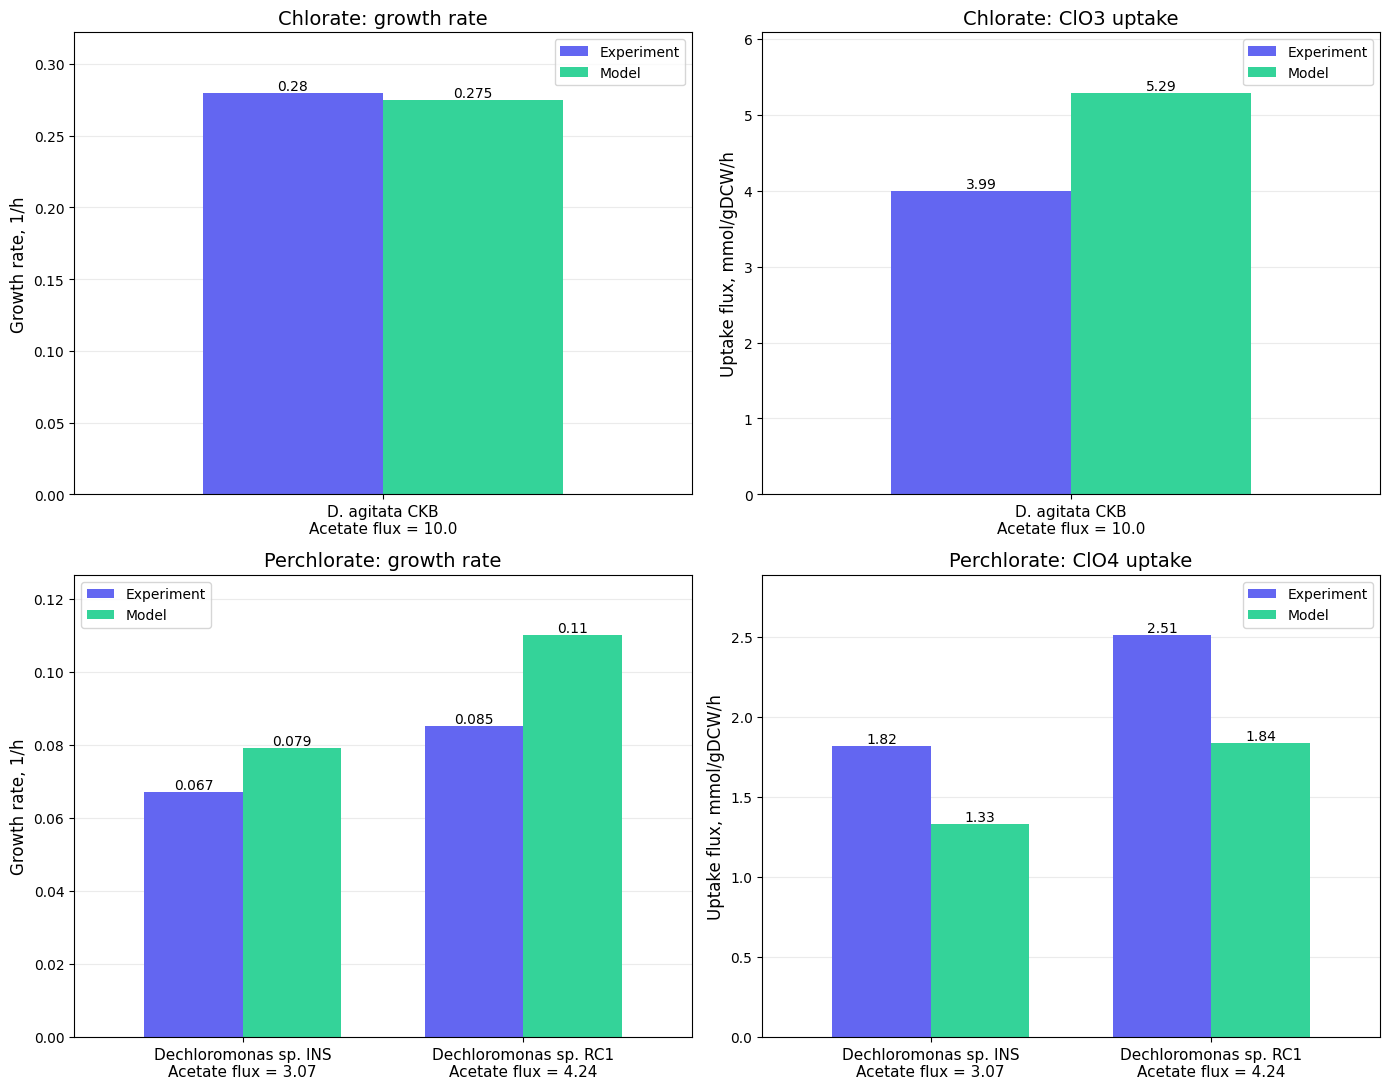

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

chlorate = [("D. agitata CKB", 10.0, 0.28, 0.275, 3.99, 5.291)]
perchlorate = [("Dechloromonas sp. INS", 3.07, 0.067, 0.079, 1.82, 1.331),
               ("Dechloromonas sp. RC1", 4.24, 0.085, 0.11, 2.51, 1.838)]

c_exp, c_mod = "#6366f1", "#34d399"
w = 0.35

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

rows = [("Chlorate", chlorate, "ClO3"), ("Perchlorate", perchlorate, "ClO4")]
for r, (acc, data, formula) in enumerate(rows):
    x = np.arange(len(data))
    labels = [f"{d[0]}\nAcetate flux = {d[1]}" for d in data]
    panels = [(2, 3, "Growth rate, 1/h", f"{acc}: growth rate"),
              (4, 5, "Uptake flux, mmol/gDCW/h", f"{acc}: {formula} uptake")]
    for c, (i_exp, i_mod, ylabel, title) in enumerate(panels):
        ax = axes[r, c]
        e = [d[i_exp] for d in data]
        m = [d[i_mod] for d in data]
        b1 = ax.bar(x - w/2, e, w, color=c_exp, label="Experiment")
        b2 = ax.bar(x + w/2, m, w, color=c_mod, label="Model")
        for b in list(b1) + list(b2):
            ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3g}",
                    ha="center", va="bottom", fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=11)
        ax.set_xlim(-0.6, len(data) - 1 + 0.6)
        ax.set_ylim(0, max(e + m) * 1.15)
        ax.set_ylabel(ylabel, fontsize=12)
        ax.set_title(title, fontsize=14)
        ax.legend(fontsize=10)
        ax.grid(True, axis="y", alpha=0.25)
        ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("pcrb_experiment_vs_model.png", dpi=1200)
plt.show()

In [ ]:
import plotly.graph_objects as go
import pandas as pd
from io import StringIO

data = []

micom_raw = """metabolite\tfocal\tpartner\tclass\tsample_id
cl_e\tagitata\tmcaps\tprovided\tsample_1_8
co2_e\tagitata\tmcaps\tprovided\tsample_1_8
fald_e\tagitata\tmcaps\treceived\tsample_1_8
fum_e\tagitata\tmcaps\treceived\tsample_1_8
h2o_e\tagitata\tmcaps\treceived\tsample_1_8
h_e\tagitata\tmcaps\treceived\tsample_1_8
mal__L_e\tagitata\tmcaps\tprovided\tsample_1_8
pheme_e\tagitata\tmcaps\treceived\tsample_1_8
ser__L_e\tagitata\tmcaps\treceived\tsample_1_8
succ_e\tagitata\tmcaps\tprovided\tsample_1_8
thr__L_e\tagitata\tmcaps\tprovided\tsample_1_8
cl_e\tagitata\tmcaps\tprovided\tsample_1_9
co2_e\tagitata\tmcaps\tprovided\tsample_1_9
fald_e\tagitata\tmcaps\treceived\tsample_1_9
fum_e\tagitata\tmcaps\treceived\tsample_1_9
h2o_e\tagitata\tmcaps\treceived\tsample_1_9
h_e\tagitata\tmcaps\treceived\tsample_1_9
mal__L_e\tagitata\tmcaps\tprovided\tsample_1_9
pheme_e\tagitata\tmcaps\treceived\tsample_1_9
ser__L_e\tagitata\tmcaps\treceived\tsample_1_9
succ_e\tagitata\tmcaps\tprovided\tsample_1_9
thr__L_e\tagitata\tmcaps\tprovided\tsample_1_9
ac_e\tagitata\tzr20\treceived\tsample_2_2
fe2_e\tagitata\tzr20\tprovided\tsample_2_2
h_e\tagitata\tzr20\treceived\tsample_2_2
o2_e\tagitata\tzr20\tprovided\tsample_2_2
ac_e\tagitata\tzr20\treceived\tsample_2_3
fe2_e\tagitata\tzr20\tprovided\tsample_2_3
h_e\tagitata\tzr20\treceived\tsample_2_3
o2_e\tagitata\tzr20\tprovided\tsample_2_3
ac_e\tagitata\talbum\treceived\tsample_3_2
h_e\tagitata\talbum\treceived\tsample_3_2
no2_e\tagitata\talbum\treceived\tsample_3_2
val__L_e\tagitata\talbum\tprovided\tsample_3_2
ac_e\tagitata\talbum\treceived\tsample_3_3
h_e\tagitata\talbum\treceived\tsample_3_3
no2_e\tagitata\talbum\treceived\tsample_3_3
val__L_e\tagitata\talbum\tprovided\tsample_3_3
"""
micom_new = pd.read_csv(StringIO(micom_raw), sep='\t')
partner_to_species = {'mcaps': 'M. capsulatus', 'zr20': 'M. alcaliphilum', 'album': 'M. album'}

met_names = {
    'cl_e': 'Chloride', 'co2_e': 'CO2', 'fald_e': 'Formaldehyde', 'fum_e': 'Fumarate',
    'h2o_e': 'H2O', 'h_e': 'Protons', 'mal__L_e': 'Malate', 'pheme_e': 'Heme',
    'ser__L_e': 'Serine', 'succ_e': 'Succinate', 'thr__L_e': 'Threonine',
    'ac_e': 'Acetate', 'fe2_e': 'Fe2+', 'o2_e': 'Oxygen',
    'no2_e': 'Nitrite', 'val__L_e': 'Valine'
}

flip = {'provided': 'Received', 'received': 'Provided'}

for _, r in micom_new.iterrows():
    data.append({
        'Species': partner_to_species[r['partner']],
        'Sample': r['sample_id'],
        'Platform': 'MICOM',
        'Type': flip[r['class']],
        'Compound': met_names[r['metabolite']]
    })

# M. capsulatus, sample_1_8
for compound in ['Protons', 'Malate', 'Serine', 'Heme', 'Formaldehyde', 'Fumarate']: data.append({'Species': 'M. capsulatus', 'Sample': 'sample_1_8', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen', 'Chloride', 'Succinate', 'Na+', 'CO2', 'Threonine']: data.append({'Species': 'M. capsulatus', 'Sample': 'sample_1_8', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

# M. capsulatus, sample_1_9
for compound in ['Protons', 'Malate', 'Serine', 'Heme', 'Formaldehyde']: data.append({'Species': 'M. capsulatus', 'Sample': 'sample_1_9', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen', 'Chloride', 'Succinate', 'Na+', 'CO2', 'Threonine']: data.append({'Species': 'M. capsulatus', 'Sample': 'sample_1_9', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

# M. album, sample_3_2
for compound in ['Lactate']: data.append({'Species': 'M. album', 'Sample': 'sample_3_2', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen', 'Chloride', 'Valine']: data.append({'Species': 'M. album', 'Sample': 'sample_3_2', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

# M. album, sample_3_3
for compound in ['Lactate']: data.append({'Species': 'M. album', 'Sample': 'sample_3_3', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen', 'Chloride', 'Valine']: data.append({'Species': 'M. album', 'Sample': 'sample_3_3', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

# M. alcaliphilum, sample_2_2
for compound in ['Protons', 'Acetate']: data.append({'Species': 'M. alcaliphilum', 'Sample': 'sample_2_2', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen']: data.append({'Species': 'M. alcaliphilum', 'Sample': 'sample_2_2', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

# M. alcaliphilum, sample_2_3
for compound in ['Protons', 'Acetate', 'Lactate']: data.append({'Species': 'M. alcaliphilum', 'Sample': 'sample_2_3', 'Platform': 'PyCoMo', 'Type': 'Provided', 'Compound': compound})
for compound in ['Oxygen']: data.append({'Species': 'M. alcaliphilum', 'Sample': 'sample_2_3', 'Platform': 'PyCoMo', 'Type': 'Received', 'Compound': compound})

df = pd.DataFrame(data)

sankey_df = df.copy()
sankey_df['source_node'] = sankey_df['Platform'] + ' ' + sankey_df['Type']
links_df = sankey_df.groupby(['source_node', 'Compound']).size().reset_index(name='value')

labels = list(pd.concat([links_df['source_node'], links_df['Compound']]).unique())

colors = {
    'MICOM': 'rgba(188, 179, 216, 1.0)',
    'PyCoMo': 'rgba(254, 186, 237, 1.0)',
    'Mixed_Bar': 'rgba(221, 183, 227, 1.0)',
    'MICOM_light': 'rgba(188, 179, 216, 0.4)',
    'PyCoMo_light': 'rgba(254, 186, 237, 0.4)',
    'Metabolite': 'lightgrey',
    'background': 'white'
}

node_colors = []
for label in labels:
    if label.startswith('MICOM'): node_colors.append(colors['MICOM'])
    elif label.startswith('PyCoMo'): node_colors.append(colors['PyCoMo'])
    else: node_colors.append(colors['Metabolite'])

link_colors = []
for source_node_name in links_df['source_node']:
    if source_node_name.startswith('MICOM'): link_colors.append(colors['MICOM_light'])
    else: link_colors.append(colors['PyCoMo_light'])

source_indices = links_df['source_node'].map(lambda x: labels.index(x))
target_indices = links_df['Compound'].map(lambda x: labels.index(x))

def jaccard(set1, set2):
    if not set1 or not set2: return 0
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union if union > 0 else 0

grouped_all = df.groupby(['Species', 'Sample', 'Platform'])['Compound'].apply(set).reset_index()

pivot_all = grouped_all.pivot_table(index=['Species', 'Sample'], columns='Platform', values='Compound', aggfunc='first')

results_all = []
for idx in pivot_all.index:
    species, sample = idx
    micom_set = pivot_all.loc[idx, 'MICOM']
    pycomo_set = pivot_all.loc[idx, 'PyCoMo']
    j_all = jaccard(micom_set, pycomo_set)
    results_all.append({
        'Species': species,
        'Sample': sample,
        'Jaccard_All': j_all
    })

results_all_df = pd.DataFrame(results_all).sort_values(['Species', 'Sample'])
results_all_df['Sample_Short'] = results_all_df['Sample'].str.replace('sample_', 'S')
x_labels = [f"{row['Species']}<br>{row['Sample_Short']}" for _, row in results_all_df.iterrows()]

layout = go.Layout(
    width=1400, height=600,
    plot_bgcolor=colors['background'],
    paper_bgcolor=colors['background'],
    showlegend=False,
    margin=dict(l=50, r=40, t=80, b=80),

    xaxis=dict(domain=[0.55, 1], title="<b>Species / Sample</b>", tickfont=dict(size=11), showline=True, linewidth=1, linecolor='black'),
    yaxis=dict(domain=[0, 1], title="<b>Jaccard Index</b>", range=[0, 1.15], tickvals=[0, 0.2, 0.4, 0.6, 0.8, 1.0], gridcolor='lightgrey', showline=True, linewidth=1, linecolor='black', zeroline=True, zerolinecolor='black'),

    annotations=[
        dict(x=0.0, y=1.05, xref="paper", yref="paper", text="<b>А</b>", showarrow=False, font=dict(size=24, color="black"), xanchor="left", yanchor="bottom"),
        dict(x=0.55, y=1.05, xref="paper", yref="paper", text="<b>B</b>", showarrow=False, font=dict(size=24, color="black"), xanchor="left", yanchor="bottom")
    ],

    shapes=[
        dict(type="line", x0=0.55, x1=1, y0=0.5, y1=0.5, xref="paper", yref="y", line=dict(color="gray", width=1, dash="dash"), opacity=0.5)
    ]
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Sankey(
    domain=dict(x=[0, 0.45], y=[0, 1.0]),
    node=dict(pad=15, thickness=20, line=dict(color="black", width=0.5), label=labels, color=node_colors),
    link=dict(source=source_indices, target=target_indices, value=links_df['value'], color=link_colors),
    textfont=dict(size=14)
))

fig.add_trace(go.Bar(
    x=x_labels, y=results_all_df['Jaccard_All'], xaxis='x', yaxis='y',
    width=0.45, name='Aggregated Jaccard',
    marker_color=colors['Mixed_Bar'], marker_line_color='black', marker_line_width=0.5,
    text=results_all_df['Jaccard_All'].round(2), textposition='outside', textfont=dict(size=14, color='black'),
    hovertemplate='<b>%{x}</b><br>Overall Jaccard Index: %{y:.3f}<extra></extra>'
))

fig.show()